# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [1]:
# Write your code here
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"seaborn version: {sns.__version__}")


# complete

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.4.6
Pandas version: 2.2.3
matplotlib version: 3.10.0
seaborn version: 0.13.2


In [ ]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [2]:
# Write your code here

S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Compute linear combination z
z = S @ theta + 0.5

# 2. Compute sigmoid probabilities and predict spam (probability >= 0.5)
probabilities = 1 / (1 + np.exp(-z))

# Identify predicted spam emails
predicted_spam = probabilities >= 0.5

In [ ]:
# Auto-graded cell (S)
# Skip it

In [ ]:
# Auto-graded cell (theta)
# Skip it

In [ ]:
# Auto-graded cell (bias)
# Skip it

In [ ]:
# Auto-graded cell (z)
# Skip it

In [ ]:
# Auto-graded cell (probabilities)
# Skip it

In [ ]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [3]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [ ]:
# Auto graded cell (log)
# skip it

In [4]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"
idx = rng.choice(300, 12, replace=False)
log.loc[idx, "failed_attempts"] = rng.integers(5, 11, 12)
# Write your code here

In [ ]:
# Autograded cell (Failed attempts)
# Skip it

In [5]:
# Insert 10 missing values randomly
log.loc[rng.choice(log.index, 10, replace=False), "failed_attempts"] = np.nan
# Write your code here

In [ ]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [6]:
# Write your code here
ru_log_at_least_five_attempts = len(log[(log["country"] == "RU") & (log["failed_attempts"] >= 5)])

In [ ]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [7]:
# Write your code here
user_max_failed_attempts = log.groupby("user")["failed_attempts"].sum().sort_values(ascending=False)

In [ ]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [8]:
# Write your code here
log['long_session'] = (log["duration_min"] > 30).astype(int)

In [ ]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

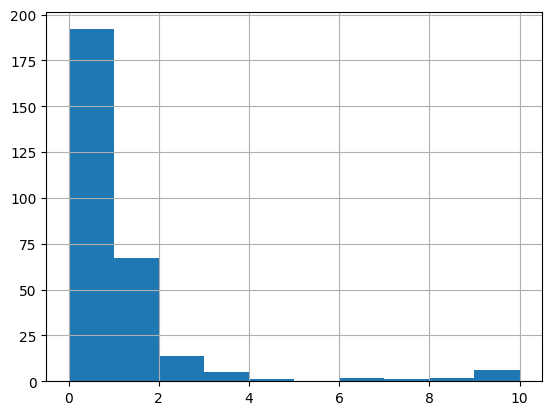

In [9]:
# Draw the histogram of failed_attempts.
log["failed_attempts"].hist()
plt.show()
# Write your code here

In [ ]:
# Auto-graded cell - Skip it...

In [ ]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

In [ ]:
# Write your code here
# answer_q2 = B

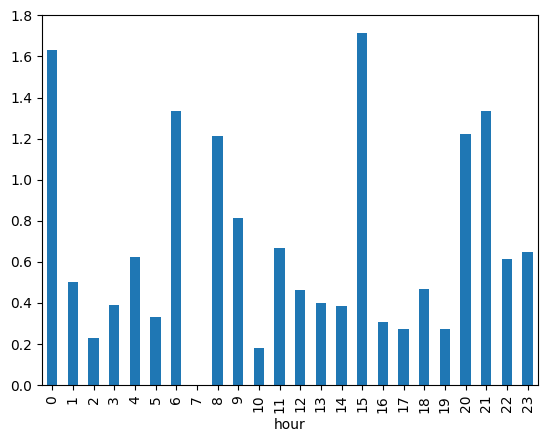

In [11]:
# 3. Draw a bar chart of the mean failed_attempts per night value.
log.groupby("hour")["failed_attempts"].mean().plot(kind="bar")
plt.show()
# Write your code here

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
# Write your code here
# Please write a sentence response instead of code
X[:, 2] returns all rows of the third column of X.

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [ ]:
# Write your code here
df.isnull().sum()

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
# Write your code here
A boxplot

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
# Write your code here
We scale features to make their values comparable so the model learns better.

Commit the logins_clean.csv.(0.5 point)

In [12]:
# save the cleaned table in login_clean.csv
log.to_csv("logins_clean.csv", index=False)
from google.colab import files
files.download("logins_clean.csv")
# Write your code here

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [17]:
# Write your code here
cols = ["hour", "failed_attempts", "duration_min", "night"]
df["night"] = ((df["hour"] < 6) | (df["hour"] >= 22)).astype(int)
X = df[cols].to_numpy()

from sklearn.preprocessing import StandardScaler

X = StandardScaler().fit_transform(X)

print(X.shape)

(300, 4)


In [ ]:
import numpy as np
import pandas as pd
